# Week 2 – Seoul Bike Sharing
**System:** Bike rentals in Seoul.  
**Data:** [UCI Seoul Bike Sharing Demand](https://archive.ics.uci.edu/dataset/560/seoul+bike+sharing+demand).  
**Goal:** Explore real data and compare simple weather scenarios.

## 1. Load data
Download the CSV and put `SeoulBikeData.csv` next to this notebook.

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

In [5]:
df = pd.read_csv('SeoulBikeData.csv', encoding='latin1')
df.head()

,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
0,01/12/2017,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,01/12/2017,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,01/12/2017,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,01/12/2017,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,01/12/2017,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


## 2. Explore data

In [6]:
print(df.shape)
print(df.columns.tolist())

(8760, 14)
['Date', 'Rented Bike Count', 'Hour', 'Temperature(°C)', 'Humidity(%)', 'Wind speed (m/s)', 'Visibility (10m)', 'Dew point temperature(°C)', 'Solar Radiation (MJ/m2)', 'Rainfall(mm)', 'Snowfall (cm)', 'Seasons', 'Holiday', 'Functioning Day']


## 3. Clean data
Remove missing values, invalid rentals, and unrealistic weather readings.

In [7]:
df = df.dropna()
print('Rows after removing missing values:', len(df))

Rows after removing missing values: 8760


In [8]:
df = df[df['Rented Bike Count'] >= 0]
df = df[df['Functioning Day'] == 'Yes']
print('Rows after filtering:', len(df))

Rows after filtering: 8465


In [9]:
df = df[(df['Temperature(°C)'] >= -30) & (df['Temperature(°C)'] <= 50)]
df = df[(df['Humidity(%)'] >= 0) & (df['Humidity(%)'] <= 100)]
print('Rows after temperature and humidity checks:', len(df))

Rows after temperature and humidity checks: 8465


In [10]:
df = df[(df['Rainfall(mm)'] >= 0) & (df['Wind speed (m/s)'] >= 0)]
print('Clean rows:', len(df))

Clean rows: 8465


## 4. Select one day
Use the first day with 24 hourly observations.

In [11]:
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)
df = df.sort_values(['Date', 'Hour'])
full_days = df.groupby('Date').filter(lambda day: len(day) == 24)
selected_date = full_days['Date'].iloc[0]
day = full_days[full_days['Date'] == selected_date].copy()
print('Selected day:', selected_date.date())

Selected day: 2017-12-01


## 5. Plot observations

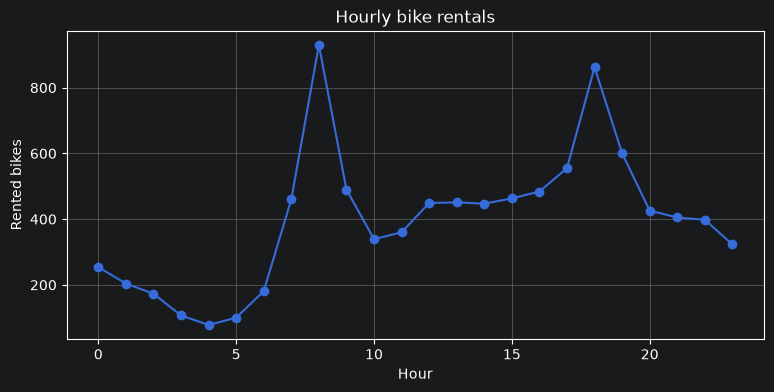

In [12]:
plt.figure(figsize=(9, 4))
plt.plot(day['Hour'], day['Rented Bike Count'], marker='o')
plt.title('Hourly bike rentals')
plt.xlabel('Hour')
plt.ylabel('Rented bikes')
plt.grid(True)
plt.show()

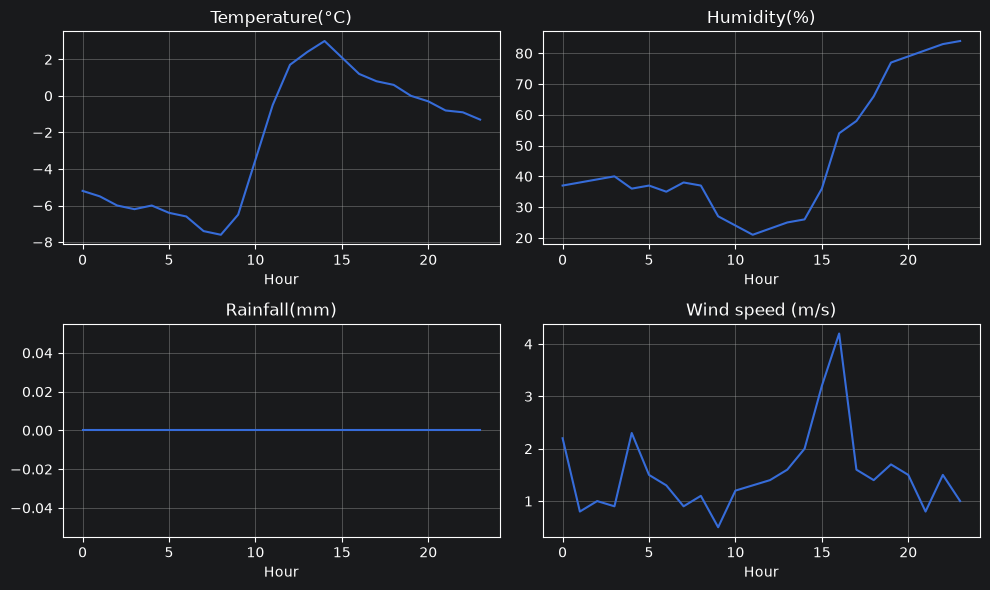

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6))
columns = ['Temperature(°C)', 'Humidity(%)', 'Rainfall(mm)', 'Wind speed (m/s)']
for ax, column in zip(axes.flat, columns):
    ax.plot(day['Hour'], day[column])
    ax.set_title(column)
    ax.set_xlabel('Hour')
    ax.grid(True)
plt.tight_layout()
plt.show()

## 6. Scenario function
**Assumptions (not measured effects):** +1 mm rain → −6%, +1 °C → −1.5%, +1 humidity point → −0.4%, +1 m/s wind → −3%.

In [14]:
def simulate_bikes(rentals, rain=0, temperature=0, humidity=0, wind=0):
    factor = 1 - 0.06 * rain - 0.015 * temperature - 0.004 * humidity - 0.03 * wind
    factor = max(0, factor)
    return rentals * factor

## 7. Three scenarios
1. Rain: +5 mm.  
2. Hot and humid: +8 °C and +15 humidity points.  
3. Windy: +8 m/s.

In [15]:
day['Baseline'] = day['Rented Bike Count']
day['Rainy'] = simulate_bikes(day['Baseline'], rain=5)
day['Hot and humid'] = simulate_bikes(day['Baseline'], temperature=8, humidity=15)
day['Windy'] = simulate_bikes(day['Baseline'], wind=8)

## 8. Compare scenarios

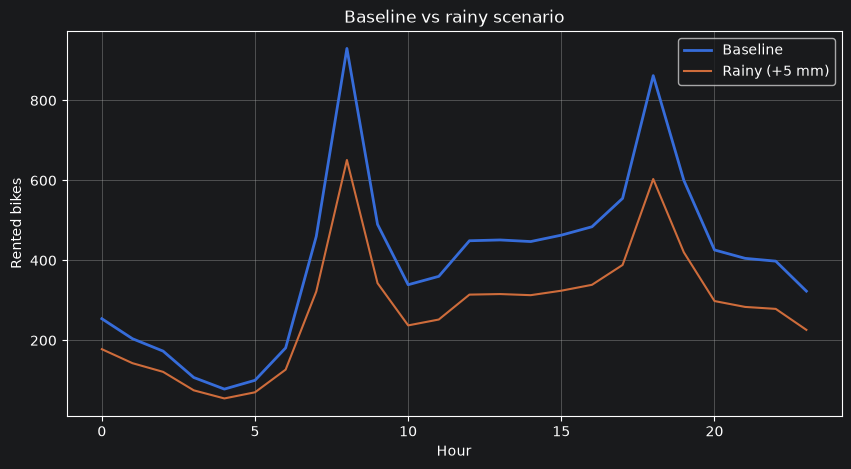

In [16]:
plt.figure(figsize=(10, 5))
plt.plot(day['Hour'], day['Baseline'], label='Baseline', linewidth=2)
plt.plot(day['Hour'], day['Rainy'], label='Rainy (+5 mm)')
plt.xlabel('Hour')
plt.ylabel('Rented bikes')
plt.title('Baseline vs rainy scenario')
plt.legend()
plt.grid(True)
plt.show()

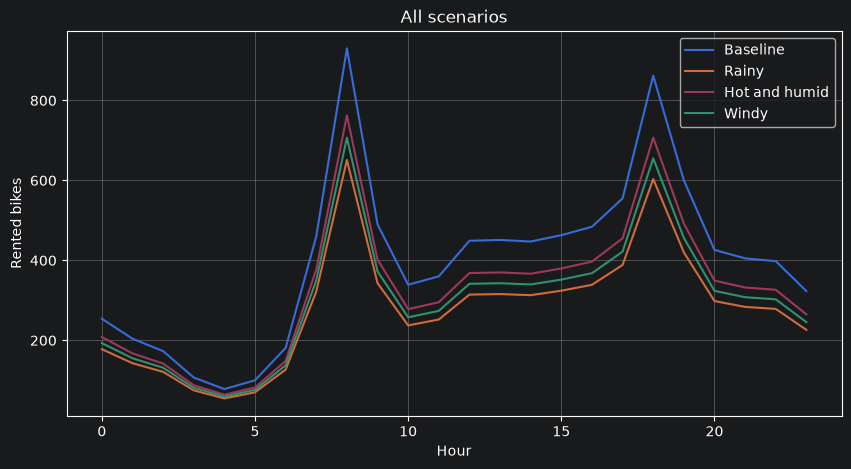

In [17]:
plt.figure(figsize=(10, 5))
for name in ['Baseline', 'Rainy', 'Hot and humid', 'Windy']:
    plt.plot(day['Hour'], day[name], label=name)
plt.xlabel('Hour')
plt.ylabel('Rented bikes')
plt.title('All scenarios')
plt.legend()
plt.grid(True)
plt.show()

Baseline         9539.0
Rainy            6677.0
Hot and humid    7822.0
Windy            7250.0
dtype: float64


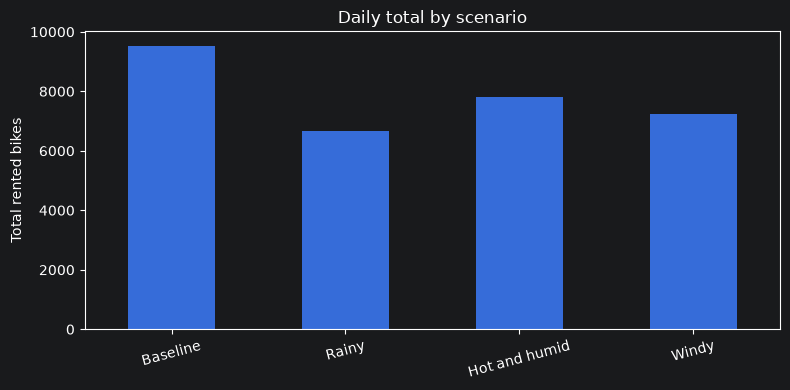

In [18]:
totals = day[['Baseline', 'Rainy', 'Hot and humid', 'Windy']].sum()
print(totals.round(0))
plt.figure(figsize=(8, 4))
totals.plot(kind='bar')
plt.ylabel('Total rented bikes')
plt.title('Daily total by scenario')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

**Note:** The scenario percentages are illustrative assumptions. They do not prove how weather changes actual demand. This is a Week 2 exploratory simulation, not a predictive model.